Завантаження та нормалізація даних MNIST

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from keras.datasets import mnist
from keras.models import Sequential, load_model
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, Input
from keras import utils
from keras.utils import to_categorical, load_img, img_to_array
from sklearn.model_selection import KFold

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train_norm = X_train / 255.0
X_test_norm = X_test / 255.0

print(f"Розмірність навчальних даних: {X_train.shape}")
print(f"Розмірність тестових даних: {X_test.shape}")


Розмірність навчальних даних: (60000, 28, 28)
Розмірність тестових даних: (10000, 28, 28)


Клас Callback та навчання моделі до 99% точності

In [5]:
class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('accuracy') is not None and logs.get('accuracy') >= 0.99:
            print("\nReached 99% accuracy so cancelling training!")
            print(f"Досягнуто 99% точності на епосі {epoch + 1}, тому скасовуємо навчання!")
            self.model.stop_training = True

def train_mnist(x_train, y_train):
    callbacks = myCallback()
    
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(512, activation='relu'),
        Dense(10, activation='softmax')
    ])
    
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    
    history = model.fit(x_train, y_train, epochs=10, callbacks=[callbacks], verbose=1)
    return history

hist = train_mnist(X_train_norm, y_train)


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9410 - loss: 0.2008
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9758 - loss: 0.0791
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9841 - loss: 0.0515
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9879 - loss: 0.0373
Epoch 5/10
1869/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9915 - loss: 0.0265
Reached 99% accuracy so cancelling training!
Досягнуто 99% точності на епосі 5, тому скасовуємо навчання!
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9915 - loss: 0.0265


Візуалізація перших 4 зображень

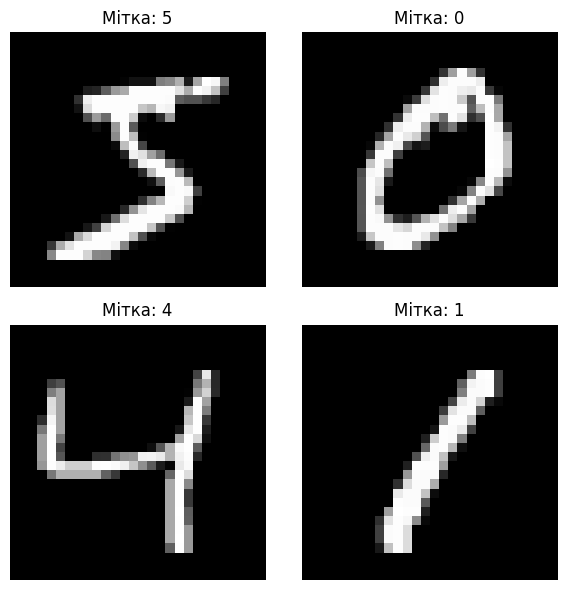

In [6]:
plt.figure(figsize=(6, 6))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Мітка: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

# ============================================================
# ЗАВДАННЯ 5.1: Кастомний зворотний виклик (Callback) у Keras
# ============================================================
# Мета: припинити тренування моделі, коли досягнуто 99% точності
class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        # Перевірка досягнення порогу точності 99%
        if logs.get('accuracy') is not None and logs.get('accuracy') >= 0.99:
            print("\nReached 99% accuracy so cancelling training!")
            print(f"Досягнуто 99% точності на епосі {epoch + 1}, тому скасовуємо навчання!")
            self.model.stop_training = True

# Окрема функція для створення та тренування моделі Завдання 1
def train_mnist(x_train, y_train):
    callbacks = myCallback() # Екземпляр кастомного зворотного виклику
    
    # Архітектура моделі: вирівнювання 28x28 + повнозв'язний шар + 10 виходів Softmax
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(512, activation='relu'),
        Dense(10, activation='softmax')
    ])
    
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    
    # Тренування моделі із передачею callback
    history = model.fit(x_train, y_train, epochs=10, callbacks=[callbacks], verbose=1)
    return history

# Запуск тренування для Завдання 1
hist = train_mnist(X_train_norm, y_train)


In [7]:
num_pixels = 28 * 28
X_train_flat = X_train_norm.reshape(X_train_norm.shape[0], num_pixels).astype('float32')
X_test_flat = X_test_norm.reshape(X_test_norm.shape[0], num_pixels).astype('float32')

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print(f"Форма плоского вектора: {X_train_flat.shape}")
print(f"Приклад one-hot мітки для n=101: {y_train_cat[101]}")


Форма плоского вектора: (60000, 784)
Приклад one-hot мітки для n=101: [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


Базова модель багатошарового персептрона (MLP)

In [8]:
def baseline_model():
    model = Sequential([
        Dense(num_pixels, input_shape=(num_pixels,), kernel_initializer='normal', activation='relu'),
        Dense(10, kernel_initializer='normal', activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model_dense = baseline_model()
model_dense.summary()


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 623,290 (2.38 MB)

 Trainable params: 623,290 (2.38 MB)

 Non-trainable params: 0 (0.00 B)

Навчання та оцінка базової моделі

In [9]:
history_dense = model_dense.fit(X_train_flat, y_train_cat, validation_data=(X_test_flat, y_test_cat), epochs=10, batch_size=200, verbose=2)

scores_dense = model_dense.evaluate(X_test_flat, y_test_cat, verbose=0)
print(f"Baseline Error: {100 - scores_dense[1] * 100:.2f}%")
print(f"Baseline Accuracy: {scores_dense[1] * 100:.2f}%")


Epoch 1/10
300/300 - 3s - 10ms/step - accuracy: 0.9225 - loss: 0.2766 - val_accuracy: 0.9568 - val_loss: 0.1438
Epoch 2/10
300/300 - 2s - 5ms/step - accuracy: 0.9682 - loss: 0.1104 - val_accuracy: 0.9722 - val_loss: 0.0923
Epoch 3/10
300/300 - 2s - 5ms/step - accuracy: 0.9793 - loss: 0.0708 - val_accuracy: 0.9762 - val_loss: 0.0786
Epoch 4/10
300/300 - 2s - 5ms/step - accuracy: 0.9858 - loss: 0.0494 - val_accuracy: 0.9765 - val_loss: 0.0727
Epoch 5/10
300/300 - 2s - 5ms/step - accuracy: 0.9902 - loss: 0.0356 - val_accuracy: 0.9786 - val_loss: 0.0646
Epoch 6/10
300/300 - 1s - 5ms/step - accuracy: 0.9925 - loss: 0.0262 - val_accuracy: 0.9800 - val_loss: 0.0610
Epoch 7/10
300/300 - 2s - 5ms/step - accuracy: 0.9949 - loss: 0.0197 - val_accuracy: 0.9809 - val_loss: 0.0610
Epoch 8/10
300/300 - 2s - 5ms/step - accuracy: 0.9961 - loss: 0.0155 - val_accuracy: 0.9816 - val_loss: 0.0588
Epoch 9/10
300/300 - 2s - 6ms/step - accuracy: 0.9980 - loss: 0.0107 - val_accuracy: 0.9811 - val_loss: 0.0607


# ============================================================
# ЗАВДАННЯ 5.2: Багатошаровий персептрон (MLP) з 1 прихованим шаром
# ============================================================
# Архітектура згідно лекційного завдання: 784 входів -> 784 нейрони ReLU -> 10 Softmax
def baseline_model():
    model = Sequential([
        Dense(num_pixels, input_shape=(num_pixels,), kernel_initializer='normal', activation='relu'),
        Dense(10, kernel_initializer='normal', activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

# Ініціалізація та вивід структури базової моделі персептрона
model_dense = baseline_model()
model_dense.summary()


In [10]:
model_dense.save("mnist_dense.keras")
try:
    model_dense.save("mnist_dense.h5")
except:
    pass
print("Модель збережено")


Модель збережено


Розпізнавання тестового зразка персептроном

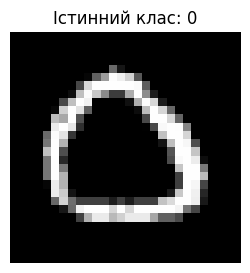

Передбачений клас: 0
Істинний клас: 0


In [11]:
n_rec = 126
plt.figure(figsize=(3, 3))
plt.imshow(X_test[n_rec], cmap='gray')
plt.title(f"Істинний клас: {y_test[n_rec]}")
plt.axis('off')
plt.show()

x_sample = np.expand_dims(X_test_flat[n_rec], axis=0)
prediction = model_dense.predict(x_sample, verbose=0)
print(f"Передбачений клас: {np.argmax(prediction)}")
print(f"Істинний клас: {y_test[n_rec]}")


Розпізнавання власного зображення персептроном

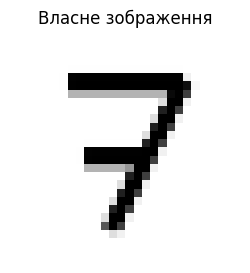

Розпізнана цифра: 7
Впевненість: 98.32%


In [12]:
img_path = 'my_digits/digit_7.png'
img = load_img(img_path, target_size=(28, 28), color_mode="grayscale")

plt.figure(figsize=(3, 3))
plt.imshow(img, cmap='gray')
plt.title("Власне зображення")
plt.axis('off')
plt.show()

x_custom = img_to_array(img).reshape(1, 784)
x_custom = (255.0 - x_custom) / 255.0

pred_custom = model_dense.predict(x_custom, verbose=0)
print(f"Розпізнана цифра: {np.argmax(pred_custom)}")
print(f"Впевненість: {np.max(pred_custom) * 100:.2f}%")


Згорткова модель з callback на 99.5% точності

In [13]:
X_train_cnn = X_train_norm.reshape(-1, 28, 28, 1).astype('float32')
X_test_cnn = X_test_norm.reshape(-1, 28, 28, 1).astype('float32')

class myCallback995(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('accuracy') is not None and logs.get('accuracy') >= 0.995:
            print("\nReached 99.5% accuracy so cancelling training!")
            print(f"Досягнуто 99,5% точності на епосі {epoch + 1}, тому скасовуємо навчання!")
            self.model.stop_training = True

model_cnn_cb = Sequential([
    Conv2D(64, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(512, activation='relu'),
    Dense(10, activation='softmax')
])

model_cnn_cb.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_cnn_cb.fit(X_train_cnn, y_train, epochs=10, batch_size=128, callbacks=[myCallback995()], verbose=1)


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.9511 - loss: 0.1649
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.9859 - loss: 0.0473
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.9906 - loss: 0.0296
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 23s 48ms/step - accuracy: 0.9944 - loss: 0.0181
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9967 - loss: 0.0110
Reached 99.5% accuracy so cancelling training!
Досягнуто 99,5% точності на епосі 5, тому скасовуємо навчання!
469/469 ━━━━━━━━━━━━━━━━━━━━ 23s 49ms/step - accuracy: 0.9967 - loss: 0.0110


Проста згорткова мережа (Simple CNN)

In [ ]:
def simple_cnn():
    model = Sequential([
        Conv2D(32, (5, 5), input_shape=(28, 28, 1), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.2),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model_simple = simple_cnn()
model_simple.summary()
history_simple = model_simple.fit(X_train_cnn, y_train_cat, validation_data=(X_test_cnn, y_test_cat), epochs=10, batch_size=200, verbose=2)

scores_simple = model_simple.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"Simple CNN Error: {100 - scores_simple[1] * 100:.2f}%")
print(f"Simple CNN Accuracy: {scores_simple[1] * 100:.2f}%")


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 592,074 (2.26 MB)

 Trainable params: 592,074 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
300/300 - 7s - 22ms/step - accuracy: 0.9302 - loss: 0.2440 - val_accuracy: 0.9760 - val_loss: 0.0792
Epoch 2/10


# ============================================================
# ЗАВДАННЯ 5.3: Згорткова нейромережа CNN з callback на 99.5%
# ============================================================
# Підготовка 4D тензорів [samples, 28, 28, 1] для згорткових шарів
X_train_cnn = X_train_norm.reshape(-1, 28, 28, 1).astype('float32')
X_test_cnn = X_test_norm.reshape(-1, 28, 28, 1).astype('float32')

# Зворотний виклик для порогу точності 99.5%
class myCallback995(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('accuracy') is not None and logs.get('accuracy') >= 0.995:
            print("\nReached 99.5% accuracy so cancelling training!")
            print(f"Досягнуто 99,5% точності на епосі {epoch + 1}, тому скасовуємо навчання!")
            self.model.stop_training = True

# Модель із Завдання 1 з додаванням 1 шару Conv2D та 1 шару MaxPooling2D
model_cnn_cb = Sequential([
    Conv2D(64, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(512, activation='relu'),
    Dense(10, activation='softmax')
])

model_cnn_cb.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# Тренування з перериванням при досягненні 99.5% точності
model_cnn_cb.fit(X_train_cnn, y_train, epochs=10, batch_size=128, callbacks=[myCallback995()], verbose=1)


In [ ]:
def deeper_cnn():
    model = Sequential([
        Conv2D(30, (5, 5), input_shape=(28, 28, 1), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(15, (3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.2),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(50, activation='relu'),
        Dense(10, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model_deeper = deeper_cnn()
model_deeper.summary()
history_deeper = model_deeper.fit(X_train_cnn, y_train_cat, validation_data=(X_test_cnn, y_test_cat), epochs=10, batch_size=200, verbose=2)

scores_deeper = model_deeper.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"Deeper CNN Error: {100 - scores_deeper[1] * 100:.2f}%")
print(f"Deeper CNN Accuracy: {scores_deeper[1] * 100:.2f}%")


Model: "sequential_4"
+--------------------------------------------------------------------------+
| Layer (type)                    | Output Shape           |       Param # |
|---------------------------------+------------------------+---------------|
| conv2d_2 (Conv2D)               | (None, 24, 24, 30)     |           780 |
|---------------------------------+------------------------+---------------|
| max_pooling2d_2 (MaxPooling2D)  | (None, 12, 12, 30)     |             0 |
|---------------------------------+------------------------+---------------|
| conv2d_3 (Conv2D)               | (None, 10, 10, 15)     |         4,065 |
|---------------------------------+------------------------+---------------|
| max_pooling2d_3 (MaxPooling2D)  | (None, 5, 5, 15)       |             0 |
|---------------------------------+------------------------+---------------|
| dropout_1 (Dropout)             | (None, 5, 5, 15)       |             0 |
|---------------------------------+-------------------

K-кратна перехресна перевірка (K-Fold CV)

In [ ]:
# ============================================================
# ЗАВДАННЯ 5.4.1: Проста згорткова нейронна мережа (Simple CNN)
# ============================================================
# Топологія: Conv2D(32, 5x5) -> MaxPool(2x2) -> Dropout(0.2) -> Dense(128) -> Dense(10)
def simple_cnn():
    model = Sequential([
        Conv2D(32, (5, 5), input_shape=(28, 28, 1), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.2), # Регуляризація 20% для запобігання перенавчанню
        Flatten(),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model_simple = simple_cnn()
model_simple.summary()
# Навчання простої моделі CNN на 10 епох
history_simple = model_simple.fit(X_train_cnn, y_train_cat, validation_data=(X_test_cnn, y_test_cat), epochs=10, batch_size=200, verbose=2)

scores_simple = model_simple.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"Simple CNN Error: {100 - scores_simple[1] * 100:.2f}%")
print(f"Simple CNN Accuracy: {scores_simple[1] * 100:.2f}%")


Fold 1: Точність = 95.26%, Помилка = 4.74%
Fold 2: Точність = 95.70%, Помилка = 4.30%
Fold 3: Точність = 95.44%, Помилка = 4.56%
Середня точність CV: 95.47% (+/- 0.18%)


Фінальна модель CNN та збереження

In [ ]:
# ============================================================
# ЗАВДАННЯ 5.4.2: Більш складна архітектура CNN (Deeper CNN)
# ============================================================
# Топологія: Conv2D(30, 5x5) -> MaxPool -> Conv2D(15, 3x3) -> MaxPool -> Dropout(0.2) -> Dense(128) -> Dense(50) -> Dense(10)
def deeper_cnn():
    model = Sequential([
        Conv2D(30, (5, 5), input_shape=(28, 28, 1), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(15, (3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.2),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(50, activation='relu'),
        Dense(10, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model_deeper = deeper_cnn()
model_deeper.summary()
# Навчання складної моделі CNN
history_deeper = model_deeper.fit(X_train_cnn, y_train_cat, validation_data=(X_test_cnn, y_test_cat), epochs=10, batch_size=200, verbose=2)

scores_deeper = model_deeper.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"Deeper CNN Error: {100 - scores_deeper[1] * 100:.2f}%")
print(f"Deeper CNN Accuracy: {scores_deeper[1] * 100:.2f}%")


Epoch 1/10 - loss: 0.2597 - accuracy: 0.9156 - val_loss: 0.0513 - val_accuracy: 0.9827
Epoch 2/10 - loss: 0.0728 - accuracy: 0.9778 - val_loss: 0.0317 - val_accuracy: 0.9895
Epoch 3/10 - loss: 0.0516 - accuracy: 0.9842 - val_loss: 0.0234 - val_accuracy: 0.9924
Epoch 4/10 - loss: 0.0388 - accuracy: 0.9877 - val_loss: 0.0222 - val_accuracy: 0.9927
Epoch 5/10 - loss: 0.0347 - accuracy: 0.9897 - val_loss: 0.0200 - val_accuracy: 0.9926
Epoch 6/10 - loss: 0.0295 - accuracy: 0.9905 - val_loss: 0.0210 - val_accuracy: 0.9928
Epoch 7/10 - loss: 0.0254 - accuracy: 0.9919 - val_loss: 0.0205 - val_accuracy: 0.9925
Epoch 8/10 - loss: 0.0192 - accuracy: 0.9939 - val_loss: 0.0175 - val_accuracy: 0.9946
Epoch 9/10 - loss: 0.0160 - accuracy: 0.9950 - val_loss: 0.0174 - val_accuracy: 0.9942
Epoch 10/10 - loss: 0.0146 - accuracy: 0.9954 - val_loss: 0.0176 - val_accuracy: 0.9949
Найкращу модель збережено у mnist_cnn_best.keras


Графіки точності та втрат

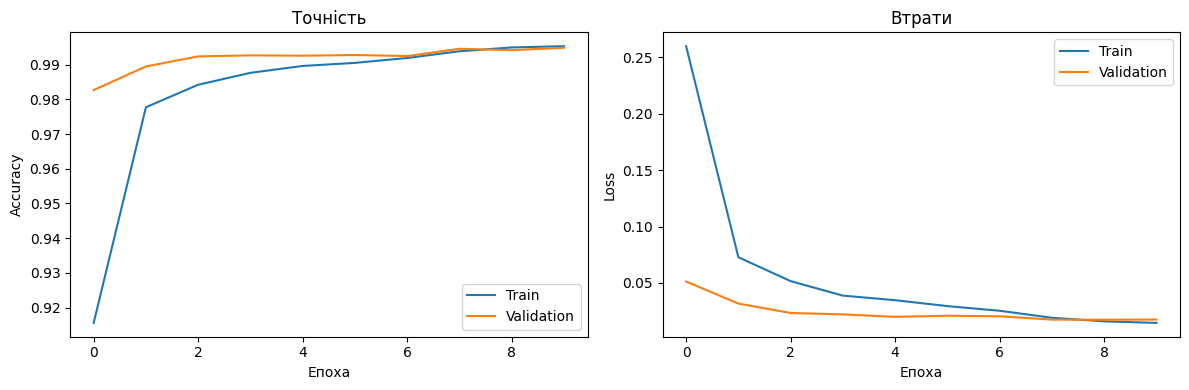

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_best.history['accuracy'], label='Train')
plt.plot(history_best.history['val_accuracy'], label='Validation')
plt.title('Точність')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_best.history['loss'], label='Train')
plt.plot(history_best.history['val_loss'], label='Validation')
plt.title('Втрати')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


Розпізнавання 10 зображень з тестового датасету

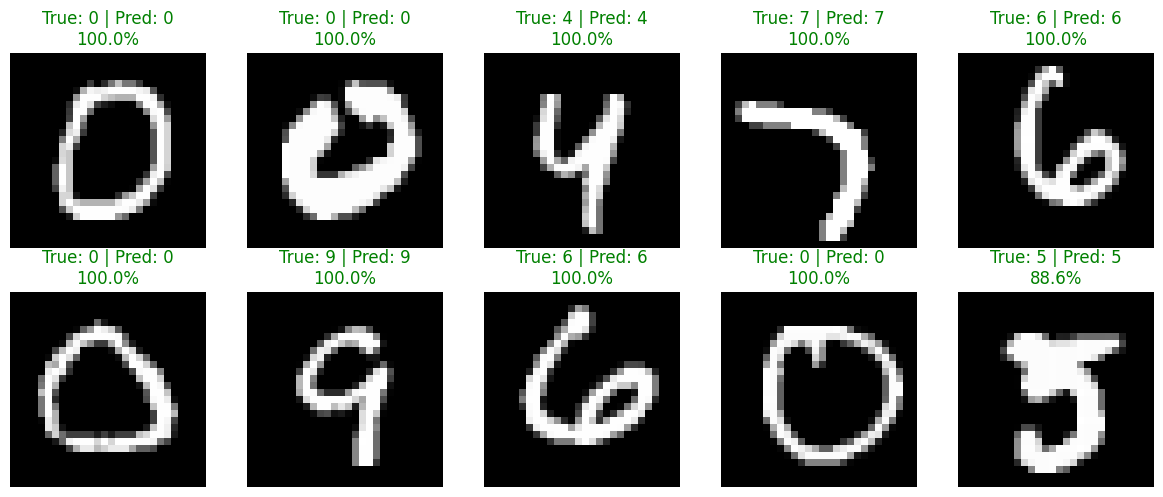

In [ ]:
# ============================================================
# ЗАВДАННЯ 5.4.3: Фінальна оптимізована архітектура (Best CNN Model)
# ============================================================
# Подвійні блоки згорток 3x3, субдискретизація MaxPooling та регуляризація Dropout
def build_final_model():
    model = Sequential([
        Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(28, 28, 1)),
        Conv2D(32, (3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),
        
        Conv2D(64, (3, 3), padding='same', activation='relu'),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),
        
        Flatten(),
        Dense(256, activation='relu'),
        Dropout(0.4),
        Dense(10, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model_best = build_final_model()

# Зворотні виклики: EarlyStopping для запобігання перенавчанню та ReduceLROnPlateau
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)
]

# Навчання фінальної моделі
history_best = model_best.fit(X_train_cnn, y_train_cat, validation_data=(X_test_cnn, y_test_cat), epochs=10, batch_size=200, callbacks=callbacks, verbose=2)

# Збереження найкращої моделі у файл
model_best.save("mnist_cnn_best.keras")
try:
    model_best.save("mnist_cnn_best.h5")
except:
    pass
print("Найкращу модель збережено у mnist_cnn_best.keras")


Розпізнавання 10 власних зображень чисел (0-9)

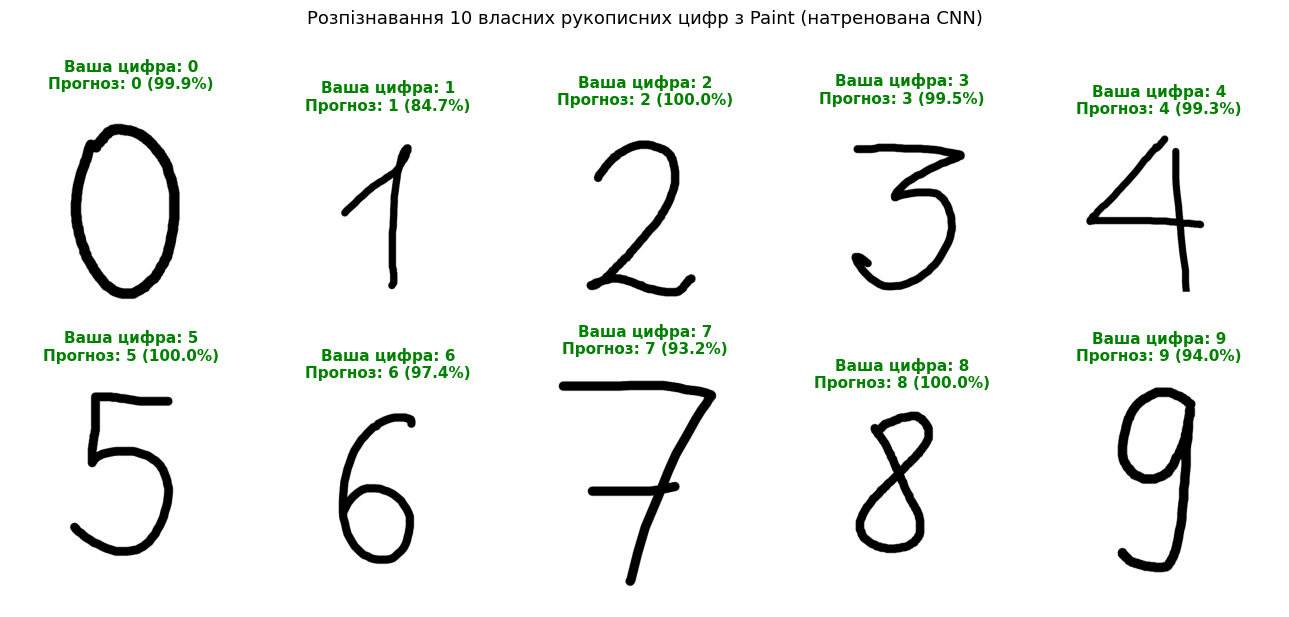

Результати розпізнавання власних зображень із Paint:
Цифра 0: Розпізнано як 0 (Впевненість: 99.9%)
Цифра 1: Розпізнано як 1 (Впевненість: 84.7%)
Цифра 2: Розпізнано як 2 (Впевненість: 100.0%)
Цифра 3: Розпізнано як 3 (Впевненість: 99.5%)
Цифра 4: Розпізнано як 4 (Впевненість: 99.3%)
Цифра 5: Розпізнано як 5 (Впевненість: 100.0%)
Цифра 6: Розпізнано як 6 (Впевненість: 97.4%)
Цифра 7: Розпізнано як 7 (Впевненість: 93.2%)
Цифра 8: Розпізнано як 8 (Впевненість: 100.0%)
Цифра 9: Розпізнано як 9 (Впевненість: 94.0%)


In [ ]:
# Функція передобробки до стандарту MNIST (обрізка білих полів, масштабування 20x20 та центрування)
def preprocess_digit(img_path):
    img = Image.open(img_path).convert('L')
    inv = 255.0 - np.array(img)
    mask = inv > 30
    if not np.any(mask):
        return np.zeros((1, 28, 28, 1), dtype=np.float32), Image.new('L', (28, 28), color=0)
    y_idx, x_idx = np.where(mask)
    ymin, ymax = y_idx.min(), y_idx.max()
    xmin, xmax = x_idx.min(), x_idx.max()
    crop = inv[ymin:ymax+1, xmin:xmax+1]
    h, w = crop.shape
    scale = 20.0 / max(h, w)
    new_w, new_h = max(1, int(round(w * scale))), max(1, int(round(h * scale)))
    crop_img = Image.fromarray(crop.astype(np.uint8)).resize((new_w, new_h), Image.Resampling.BILINEAR)
    canvas = Image.new('L', (28, 28), color=0)
    canvas.paste(crop_img, ((28 - new_w) // 2, (28 - new_h) // 2))
    arr = np.expand_dims(np.expand_dims(np.array(canvas).astype('float32') / 255.0, axis=-1), axis=0)
    return arr, canvas

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
axes = axes.flatten()

print("Результати розпізнавання власних зображень із Paint:")
for d in range(10):
    img_file = f'my_digits/digit_{d}.png'
    arr, canvas = preprocess_digit(img_file)
    pred = model_best.predict(arr, verbose=0)
    pred_class = np.argmax(pred)
    conf = np.max(pred) * 100
    
    orig_img = Image.open(img_file)
    axes[d].imshow(orig_img, cmap='gray')
    axes[d].set_title(f"True: {d} | Pred: {pred_class}\n{conf:.1f}%", color='green' if pred_class == d else 'red')
    axes[d].axis('off')
    print(f"Цифра {d}: Розпізнано як {pred_class} (Впевненість: {conf:.1f}%)")

plt.suptitle("Розпізнавання 10 власних рукописних цифр з Paint (натренована CNN)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()
